# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [29]:
import nltk
nltk.download('gutenberg')
import re
from nltk.corpus import gutenberg
# 1. Cargar los textos originales
file_ids = gutenberg.fileids()
print(f"Número de documentos: {len(file_ids)}")

raw_docs = {fid: gutenberg.raw(fid) for fid in file_ids}

# 2. Tamaño de cada documento (caracteres y palabras aproximadas)
for fid in file_ids:
    n_chars = len(raw_docs[fid])
    n_words_approx = len(raw_docs[fid].split())
    print(f"{fid:30s} | caracteres: {n_chars:8d} | palabras aprox.: {n_words_approx:7d}")

# 3. Tokenización y normalización
def normalizar_y_tokenizar(texto):
    """
    Configuración de preprocesamiento utilizada de forma consistente
    en todo el notebook:
      - Conversión a minúsculas.
      - Eliminación de puntuación, dígitos y caracteres especiales
        (se conservan solo letras).
      - Tokenización por espacios una vez limpio el texto.
    """
    texto = texto.lower()
    texto = re.sub(r"[^a-záéíóúñü]+", " ", texto)
    tokens = texto.split()
    return tokens

documentos_tokenizados = {fid: normalizar_y_tokenizar(raw_docs[fid]) for fid in file_ids}

# Verificación rápida
ejemplo = file_ids[0]
print(f"\nEjemplo de tokens de '{ejemplo}':")
print(documentos_tokenizados[ejemplo][:20])
print(f"Total de tokens en '{ejemplo}': {len(documentos_tokenizados[ejemplo])}")

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\Jhonn22\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


Número de documentos: 18
austen-emma.txt                | caracteres:   887071 | palabras aprox.:  158167
austen-persuasion.txt          | caracteres:   466292 | palabras aprox.:   83308
austen-sense.txt               | caracteres:   673022 | palabras aprox.:  118675
bible-kjv.txt                  | caracteres:  4332554 | palabras aprox.:  821133
blake-poems.txt                | caracteres:    38153 | palabras aprox.:    6845
bryant-stories.txt             | caracteres:   249439 | palabras aprox.:   45988
burgess-busterbrown.txt        | caracteres:    84663 | palabras aprox.:   15870
carroll-alice.txt              | caracteres:   144395 | palabras aprox.:   26443
chesterton-ball.txt            | caracteres:   457450 | palabras aprox.:   81598
chesterton-brown.txt           | caracteres:   406629 | palabras aprox.:   71626
chesterton-thursday.txt        | caracteres:   320525 | palabras aprox.:   57955
edgeworth-parents.txt          | caracteres:   935158 | palabras aprox.:  166070
mel

**Configuración de preprocesamiento elegida (documentación)**

- *Minúsculas*: se normaliza todo el texto a minúsculas para que `The` y `the` cuenten como el mismo término.
- *Puntuación y caracteres especiales*: se eliminan con una expresión regular que conserva solo letras (`a-z` y vocales acentuadas/ñ), de modo que signos de puntuación, números y saltos de línea no generen tokens espurios.
- *Tokenización*: al quedar el texto limpio, se separa simplemente por espacios en blanco (`str.split()`), que es suficiente dado que ya no hay puntuación pegada a las palabras.
- Esta misma función `normalizar_y_tokenizar` se reutiliza sin cambios en la Parte B (corpus grande), tal como pide el enunciado.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [30]:
def busqueda_secuencial(termino, documentos_tokenizados):
    termino = termino.lower()
    resultados = []
    for doc_id, tokens in documentos_tokenizados.items():   # 1er lazo: documentos
        encontrado = False
        for token in tokens:                                 # 2do lazo: tokens
            if token == termino:
                encontrado = True
                break
        if encontrado:
            resultados.append(doc_id)
    return resultados

# Términos de prueba: frecuente, poco frecuente e inexistente
terminos_prueba = ["The", "and", "monster", "zzzzzz"]

for t in terminos_prueba:
    r = busqueda_secuencial(t, documentos_tokenizados)
    print(f"'{t}': {len(r)} documento(s) -> {r}")

'The': 18 documento(s) -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
'and': 18 documento(s) -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
'monster': 6 documento(s) -> ['bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chestert

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [31]:
import time

def medir_tiempo_secuencial(termino, documentos_tokenizados, n_ejecuciones=30):
    """Promedia el tiempo (en ms) de 30 ejecuciones de busqueda_secuencial."""
    tiempos_ns = []
    for _ in range(n_ejecuciones):
        inicio = time.perf_counter_ns()
        busqueda_secuencial(termino, documentos_tokenizados)
        fin = time.perf_counter_ns()
        tiempos_ns.append(fin - inicio)
    media_ns = sum(tiempos_ns) / len(tiempos_ns)
    return media_ns / 1e6  # ns -> ms

resultados_tiempo_secuencial = {}
for t in terminos_prueba:
    media_ms = medir_tiempo_secuencial(t, documentos_tokenizados)
    resultados_tiempo_secuencial[t] = media_ms
    print(f"'{t}': tiempo medio = {media_ms:.4f} ms (30 ejecuciones)")

'The': tiempo medio = 0.0202 ms (30 ejecuciones)
'and': tiempo medio = 0.0215 ms (30 ejecuciones)
'monster': tiempo medio = 68.8966 ms (30 ejecuciones)
'zzzzzz': tiempo medio = 79.7548 ms (30 ejecuciones)


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [32]:
from collections import defaultdict

def construir_indice_invertido(documentos_tokenizados):
    """Vocabulario -> conjunto de ids de documentos donde aparece cada término."""
    indice = defaultdict(set)
    for doc_id, tokens in documentos_tokenizados.items():
        for token in tokens:
            indice[token].add(doc_id)
    return indice

indice_invertido = construir_indice_invertido(documentos_tokenizados)
print(f"Tamaño del vocabulario: {len(indice_invertido)}")

# Inspección de postings y frecuencia documental (DF)
for t in terminos_prueba:
    postings = indice_invertido.get(t, set())
    print(f"'{t}': DF = {len(postings)} -> postings: {sorted(postings)}")

# --- Consulta de un término ---
def consulta_un_termino(termino, indice):
    return indice.get(termino.lower(), set())

# --- Consultas booleanas ---
def consulta_and(t1, t2, indice):
    return consulta_un_termino(t1, indice) & consulta_un_termino(t2, indice)

def consulta_or(t1, t2, indice):
    return consulta_un_termino(t1, indice) | consulta_un_termino(t2, indice)

def consulta_not(t1, indice, todos_los_docs):
    return set(todos_los_docs) - consulta_un_termino(t1, indice)

todos_los_docs = set(documentos_tokenizados.keys())

print("\nAND('the', 'monster'):", consulta_and("the", "monster", indice_invertido))
print("OR('monster', 'zzzzzz'):", consulta_or("monster", "zzzzzz", indice_invertido))
print("NOT('monster'):", len(consulta_not("monster", indice_invertido, todos_los_docs)), "documentos")

Tamaño del vocabulario: 41509
'The': DF = 0 -> postings: []
'and': DF = 18 -> postings: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
'monster': DF = 6 -> postings: ['bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'melville-moby_dick.txt', 'milton-paradise.txt']
'zzzzzz': DF = 0 -> postings: []

AND('the', 'monster'): {'bryant-stories.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'milton-paradise.txt', 'melville-moby_dick.txt', 'chesterton-ball.txt'}
OR('monster', 'zzzzzz'): {'bryant-stories.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'milton-parad

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [33]:
def medir_tiempo_indice(termino, indice, n_ejecuciones=30):
    """Promedia el tiempo (en ms) de 30 ejecuciones de consulta_un_termino."""
    tiempos_ns = []
    for _ in range(n_ejecuciones):
        inicio = time.perf_counter_ns()
        consulta_un_termino(termino, indice)
        fin = time.perf_counter_ns()
        tiempos_ns.append(fin - inicio)
    media_ns = sum(tiempos_ns) / len(tiempos_ns)
    return media_ns / 1e6

print(f"{'Término':10s} | {'Secuencial (ms)':16s} | {'Índice (ms)':12s} | ¿Coinciden?")
for t in terminos_prueba:
    r_sec = set(busqueda_secuencial(t, documentos_tokenizados))
    r_idx = consulta_un_termino(t, indice_invertido)
    t_sec = medir_tiempo_secuencial(t, documentos_tokenizados)
    t_idx = medir_tiempo_indice(t, indice_invertido)
    print(f"{t:10s} | {t_sec:16.4f} | {t_idx:12.4f} | {r_sec == r_idx}")

Término    | Secuencial (ms)  | Índice (ms)  | ¿Coinciden?
The        |           0.0186 |       0.0011 | True
and        |           0.0294 |       0.0011 | True
monster    |          63.8213 |       0.0009 | True
zzzzzz     |          88.1865 |       0.0009 | True


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [34]:
import os
import re
import zipfile
import tarfile

RUTA_ZIP = r"C:\Users\Jhonn22\Downloads\txt-files.tar.zip"
DIR_DESTINO = r"C:\Users\Jhonn22\Downloads\gutenberg_extraido"

print("Archivo ZIP encontrado:", os.path.exists(RUTA_ZIP))

os.makedirs(DIR_DESTINO, exist_ok=True)

bandera = os.path.join(DIR_DESTINO, "_extraido.flag")

if not os.path.exists(bandera):
    print("Extrayendo ZIP...")

    with zipfile.ZipFile(RUTA_ZIP, "r") as archivo_zip:
        archivo_zip.extractall(DIR_DESTINO)

    for nombre in os.listdir(DIR_DESTINO):
        if nombre.lower().endswith(".tar"):
            ruta_tar = os.path.join(DIR_DESTINO, nombre)
            print("Extrayendo TAR:", ruta_tar)

            with tarfile.open(ruta_tar, "r") as archivo_tar:
                archivo_tar.extractall(DIR_DESTINO)

    with open(bandera, "w", encoding="utf-8") as archivo:
        archivo.write("ok")

    print("Extracción finalizada.")
else:
    print("Los documentos ya fueron extraídos.")

archivos_txt = []

for raiz, carpetas, archivos in os.walk(DIR_DESTINO):
    for nombre in archivos:
        if nombre.lower().endswith(".txt"):
            archivos_txt.append(os.path.join(raiz, nombre))

print(f"Archivos .txt encontrados: {len(archivos_txt)}")


def id_gutenberg(ruta_archivo):
    base = os.path.basename(ruta_archivo)
    coincidencia = re.match(r"(\d+)", base)

    return coincidencia.group(1) if coincidencia else base


libros_por_id = {}

for ruta in archivos_txt:
    gutenberg_id = id_gutenberg(ruta)

    if gutenberg_id not in libros_por_id:
        libros_por_id[gutenberg_id] = ruta

print(f"Documentos válidos sin duplicados: {len(libros_por_id)}")

Archivo ZIP encontrado: True
Los documentos ya fueron extraídos.
Archivos .txt encontrados: 78145
Documentos válidos sin duplicados: 78145


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [35]:
def cargar_subconjunto(libros_por_id, n):
    """Carga los primeros n documentos, conservando sus ids originales de Gutenberg."""
    seleccion = dict(list(libros_por_id.items())[:n])
    docs = {}
    for gid, ruta in seleccion.items():
        with open(ruta, "r", encoding="utf-8", errors="ignore") as f:
            docs[gid] = f.read()
    return docs

# Validación del flujo completo con un subconjunto pequeño
docs_grande = cargar_subconjunto(libros_por_id, 50)
docs_grande_tok = {gid: normalizar_y_tokenizar(texto) for gid, texto in docs_grande.items()}

termino_prueba_grande = "love"

# 1-2. Búsqueda secuencial y tiempo
r_sec_grande = busqueda_secuencial(termino_prueba_grande, docs_grande_tok)
t_sec_grande = medir_tiempo_secuencial(termino_prueba_grande, docs_grande_tok)

# 3-4. Índice invertido y tiempo
indice_grande = construir_indice_invertido(docs_grande_tok)
r_idx_grande = consulta_un_termino(termino_prueba_grande, indice_grande)
t_idx_grande = medir_tiempo_indice(termino_prueba_grande, indice_grande)

# 5. Igualdad de resultados y comparación
print(f"Secuencial: {len(r_sec_grande)} docs, {t_sec_grande:.4f} ms")
print(f"Índice:     {len(r_idx_grande)} docs, {t_idx_grande:.4f} ms")
print("¿Mismos resultados?", set(r_sec_grande) == set(r_idx_grande))

# Recursos de memoria y almacenamiento utilizados
import sys
tamano_indice_bytes = sys.getsizeof(indice_grande) + sum(sys.getsizeof(v) for v in indice_grande.values())
print(f"Tamaño aproximado del índice en memoria: {tamano_indice_bytes/1024:.1f} KB")

tamano_disco = sum(os.path.getsize(r) for r in list(libros_por_id.values())[:50])
print(f"Tamaño en disco del subconjunto (50 docs): {tamano_disco/1e6:.2f} MB")

Secuencial: 42 docs, 19.7343 ms
Índice:     42 docs, 0.0008 ms
¿Mismos resultados? True
Tamaño aproximado del índice en memoria: 29643.4 KB
Tamaño en disco del subconjunto (50 docs): 23.94 MB


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

n=   50 | secuencial= 20.4449 ms | índice=  0.0016 ms | tokens=4107648
n=  100 | secuencial= 59.0092 ms | índice=  0.0013 ms | tokens=7356662
n=  250 | secuencial=154.7498 ms | índice=  0.0010 ms | tokens=19283292
n=  500 | secuencial=269.3459 ms | índice=  0.0010 ms | tokens=36334597
n= 1000 | secuencial=614.3774 ms | índice=  0.0010 ms | tokens=72466944


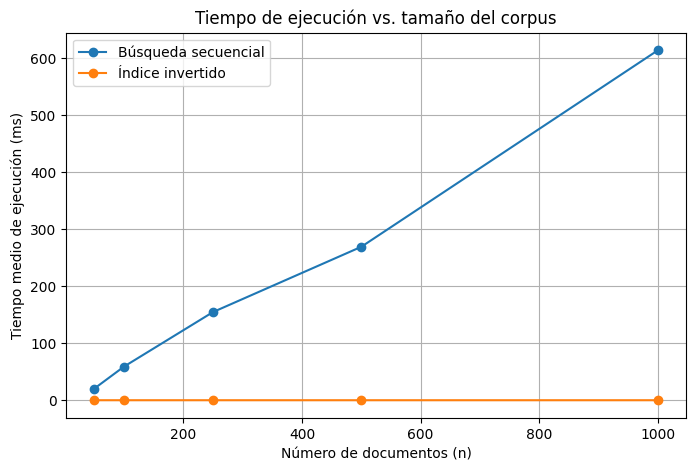

In [36]:
import matplotlib.pyplot as plt

tamanos = [50, 100, 250, 500, 1000]   # ampliar si el equipo lo permite
termino_experimento = "love"

tiempos_secuencial = []
tiempos_indice = []
total_tokens = []

for n in tamanos:
    docs_n = cargar_subconjunto(libros_por_id, n)
    docs_n_tok = {gid: normalizar_y_tokenizar(texto) for gid, texto in docs_n.items()}

    t_sec = medir_tiempo_secuencial(termino_experimento, docs_n_tok)
    indice_n = construir_indice_invertido(docs_n_tok)
    t_idx = medir_tiempo_indice(termino_experimento, indice_n)

    n_tokens = sum(len(toks) for toks in docs_n_tok.values())

    tiempos_secuencial.append(t_sec)
    tiempos_indice.append(t_idx)
    total_tokens.append(n_tokens)

    print(f"n={n:5d} | secuencial={t_sec:8.4f} ms | índice={t_idx:8.4f} ms | tokens={n_tokens}")

plt.figure(figsize=(8, 5))
plt.plot(tamanos, tiempos_secuencial, marker="o", label="Búsqueda secuencial")
plt.plot(tamanos, tiempos_indice, marker="o", label="Índice invertido")
plt.xlabel("Número de documentos (n)")
plt.ylabel("Tiempo medio de ejecución (ms)")
plt.title("Tiempo de ejecución vs. tamaño del corpus")
plt.legend()
plt.grid(True)
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

Secuencial: t(n) = 0.61335 n + -9.48667   (R² = 0.9954)
Índice:     t(n) = -0.00000 n + 0.00136   (R² = 0.5234)


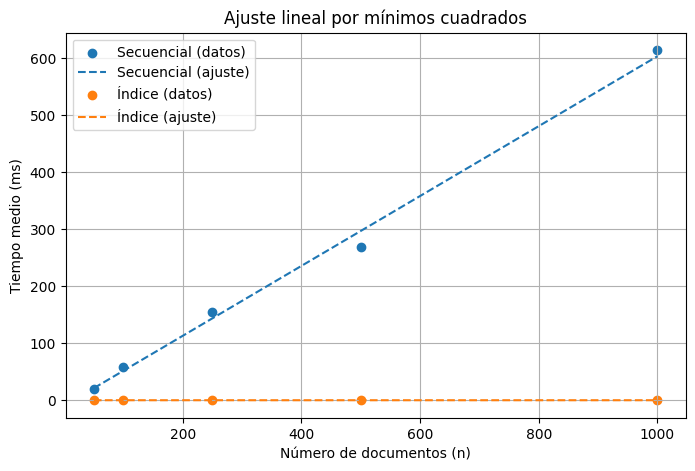

In [42]:
import numpy as np

def ajuste_lineal(x, y):
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    a, b = np.polyfit(x, y, 1)
    y_pred = a * x + b
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - ss_res / ss_tot
    return a, b, r2

a_sec, b_sec, r2_sec = ajuste_lineal(tamanos, tiempos_secuencial)
a_idx, b_idx, r2_idx = ajuste_lineal(tamanos, tiempos_indice)

print(f"Secuencial: t(n) = {a_sec:.5f} n + {b_sec:.5f}   (R² = {r2_sec:.4f})")
print(f"Índice:     t(n) = {a_idx:.5f} n + {b_idx:.5f}   (R² = {r2_idx:.4f})")

plt.figure(figsize=(8, 5))
plt.scatter(tamanos, tiempos_secuencial, color="tab:blue", label="Secuencial (datos)")
plt.plot(tamanos, a_sec * np.array(tamanos) + b_sec, color="tab:blue", linestyle="--", label="Secuencial (ajuste)")
plt.scatter(tamanos, tiempos_indice, color="tab:orange", label="Índice (datos)")
plt.plot(tamanos, a_idx * np.array(tamanos) + b_idx, color="tab:orange", linestyle="--", label="Índice (ajuste)")
plt.xlabel("Número de documentos (n)")
plt.ylabel("Tiempo medio (ms)")
plt.title("Ajuste lineal por mínimos cuadrados")
plt.legend()
plt.grid(True)
plt.show()

## 10. Interpretación de gráficas

### Interpretación de la gráfica de comparación experimental

La búsqueda secuencial debe mostrar un crecimiento más pronunciado a medida que aumenta el número de documentos, porque examina los documentos y sus tokens hasta encontrar coincidencias o completar la revisión. En cambio, el índice invertido consulta directamente la lista asociada al término; por ello, su tiempo esperado permanece prácticamente constante una vez construido el índice.

El comportamiento observado puede variar entre ejecuciones por factores del equipo, caché del sistema operativo y ruido de medición. Por esa razón se toman promedios de 30 ejecuciones. La igualdad de resultados entre secuencial e índice confirma que ambos métodos recuperan la misma colección de documentos.

### Interpretación del ajuste lineal

El coeficiente $R^2$ indica qué tan bien el modelo lineal representa los datos medidos. Valores cercanos a 1 indican mayor ajuste; una pendiente positiva confirma que el tiempo aumenta con el tamaño del corpus. Debido a la gran diferencia entre magnitudes, la gráfica comparativa se presenta en escala logarítmica para que se observen simultáneamente ambas curvas.

In [38]:
# Presentación organizada de los resultados de escalabilidad
import pandas as pd

tabla_escalabilidad = pd.DataFrame({
    "Documentos": tamanos,
    "Tiempo secuencial (ms)": tiempos_secuencial,
    "Tiempo índice (ms)": tiempos_indice,
    "Tokens totales": total_tokens
}).set_index("Documentos")

display(tabla_escalabilidad.style.format({
    "Tiempo secuencial (ms)": "{:.4f}",
    "Tiempo índice (ms)": "{:.4f}",
    "Tokens totales": "{:,.0f}"
}))

# Resumen numérico automático para apoyar la interpretación
ratio_final = tiempos_secuencial[-1] / tiempos_indice[-1]
print(f"Último tamaño evaluado: {tamanos[-1]} documentos")
print(f"Tiempo secuencial: {tiempos_secuencial[-1]:.4f} ms")
print(f"Tiempo con índice: {tiempos_indice[-1]:.4f} ms")
print(f"Razón secuencial / índice: {ratio_final:.1f} veces")
print(f"Ajuste secuencial: R² = {r2_sec:.4f}")
print(f"Ajuste del índice: R² = {r2_idx:.4f}")

,Tiempo secuencial (ms),Tiempo índice (ms),Tokens totales
Documentos,,,
50,20.4449,0.0016,"4,107,648"
100,59.0092,0.0013,"7,356,662"
250,154.7498,0.0010,"19,283,292"
500,269.3459,0.0010,"36,334,597"
1000,614.3774,0.0010,"72,466,944"


Último tamaño evaluado: 1000 documentos
Tiempo secuencial: 614.3774 ms
Tiempo con índice: 0.0010 ms
Razón secuencial / índice: 642206.4 veces
Ajuste secuencial: R² = 0.9954
Ajuste del índice: R² = 0.5234


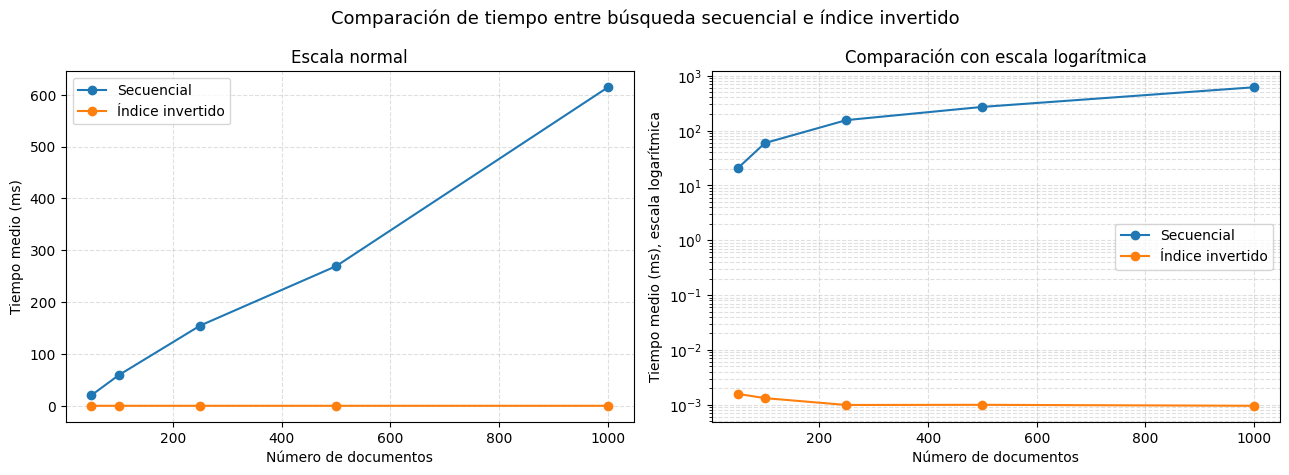

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Escala normal: permite comparar el crecimiento de la búsqueda secuencial
axes[0].plot(tamanos, tiempos_secuencial, marker="o", label="Secuencial")
axes[0].plot(tamanos, tiempos_indice, marker="o", label="Índice invertido")
axes[0].set_xlabel("Número de documentos")
axes[0].set_ylabel("Tiempo medio (ms)")
axes[0].set_title("Escala normal")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Escala logarítmica: hace visibles tiempos muy pequeños del índice
axes[1].plot(tamanos, tiempos_secuencial, marker="o", label="Secuencial")
axes[1].plot(tamanos, tiempos_indice, marker="o", label="Índice invertido")
axes[1].set_yscale("log")
axes[1].set_xlabel("Número de documentos")
axes[1].set_ylabel("Tiempo medio (ms), escala logarítmica")
axes[1].set_title("Comparación con escala logarítmica")
axes[1].legend()
axes[1].grid(True, which="both", linestyle="--", alpha=0.4)

fig.suptitle("Comparación de tiempo entre búsqueda secuencial e índice invertido", fontsize=13)
plt.tight_layout()
plt.show()

## 11. Uso de inteligencia artificial

Se utilizó una herramienta de inteligencia artificial como apoyo durante el desarrollo del trabajo, con las siguientes finalidades:

1. **Organización del código:** se sugirieron mejoras para separar las tareas de extracción, carga, normalización, búsqueda y medición.
2. **Optimización y legibilidad:** se recibieron recomendaciones para reutilizar funciones, evitar cálculos repetidos y presentar tablas y gráficas más claras.
3. **Corrección de errores:** la asistencia ayudó a identificar rutas incorrectas, diferencias entre `.tar` y `.zip` y posibles errores de ejecución en el notebook.
4. **Documentación:** se pidió apoyo para redactar explicaciones, interpretar los resultados y verificar que el procedimiento correspondiera con el enunciado.

